In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from tensorflow import keras
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import (ReduceLROnPlateau,EarlyStopping,ModelCheckpoint)
from tensorflow.keras.optimizers import AdamW
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns


In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1312s 8us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [ ]:
print("GPU Available:", tf.config.list_physical_devices('GPU'))

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
classes = [ 'airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
print("Number of classes:", len(classes))

Number of classes: 10


#Part 1: Data Preparation

In [ ]:

#Split dataset
X_train, X_val, y_train, y_val = train_test_split(X_train,y_train,test_size=0.2,random_state=42,stratify=y_train)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [ ]:
#Resizing image
IMG_SIZE = 224
BATCH_SIZE = 32
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))


In [ ]:
def resize_image(image, label):
    image = tf.image.resize(image, (224, 224))
    return image, label

In [ ]:
BATCH_SIZE = 32

train_ds = train_ds.map(resize_image).batch(BATCH_SIZE)
val_ds = val_ds.map(resize_image).batch(BATCH_SIZE)
test_ds = test_ds.map(resize_image).batch(BATCH_SIZE)

In [ ]:
#Normalization

mean = tf.constant([0.485, 0.456, 0.406])
std = tf.constant([0.229, 0.224, 0.225])

def normalize_image(image, label):
    image = image / 255.0
    image = (image - mean) / std
    return image, label
train_ds = train_ds.map(normalize_image)
val_ds = val_ds.map(normalize_image)
test_ds = test_ds.map(normalize_image)

In [ ]:
#Augmentation
data_augmentation = keras.Sequential([layers.RandomFlip("horizontal"),layers.RandomRotation(0.1),layers.RandomCrop(200, 200),layers.Resizing(224, 224)])
def augment_image(image, label):
    image = image * std + mean
    image = image * 255.0
    image = data_augmentation(image)
    image = image / 255.0
    image = (image - mean) / std
    return image, label
    train_ds = train_ds.map(augment_image)


##Why normalization must match ImageNet statistics?

Normalization must match ImageNet statistics because the pretrained CNN model (such as ResNet50) was trained using ImageNet's mean and standard deviation values. Using the same normalization for CIFAR-10 ensures that the input images have a similar distribution to the images used during pretraining. This helps the model use its previously learned features effectively and improves classification performance.

##Why augmentation improves generalization?

Data augmentation improves generalization by creating different variations of training images using techniques such as random flipping, rotation, and cropping. It helps the model learn important features instead of memorizing the training images. This reduces overfitting and enables the model to perform better on new, unseen images.

#Part 2: Model Architecture

ResNet50 is a deep CNN containing 50 layers. It uses a technique called Residual Learning, which helps train deeper neural networks effectively.

In [ ]:
#Load pretrained Resnet Model
base_model = ResNet50(weights='imagenet',include_top=False,input_shape=(224, 224, 3))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Freeze all layers of ResNet50
base_model.trainable = False
# Check whether backbone is frozen
print("ResNet50 Trainable:", base_model.trainable)

ResNet50 Trainable: False


In [ ]:
#Classifier Head
num_classes = 10
inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(512,kernel_initializer='he_normal',kernel_regularizer=regularizers.l2(0.0001))(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes,activation='softmax')(x)
model = keras.Model(inputs, outputs)

In [ ]:
# Display complete model architecture
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,643,978 (94.01 MB)

 Trainable params: 1,055,242 (4.03 MB)

 Non-trainable params: 23,588,736 (89.98 MB)

In [ ]:
# Compile the ResNet50 model
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

Why He Initialization is Suitable Here?

He Initialization is suitable because it is specifically designed for ReLU activation functions. It maintains the variance of activations, helps prevent vanishing gradients, improves training stability, and speeds up convergence.

Therefore, it helps our Dense layer learn effectively.

#Part 3: Training Strategy

In [ ]:
# Compile the ResNet50 model using AdamW optimizer
model.compile(optimizer=AdamW(learning_rate=0.0001, weight_decay=0.0001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
#Learning rate scheduler
lr_scheduler = ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=2,min_lr=0.000001,verbose=1)

In [ ]:
#Early Stopping
early_stopping = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True,verbose=1)

In [ ]:
# Save the model with the best validation loss
model_checkpoint = ModelCheckpoint('best_resnet50_model.keras',monitor='val_loss',save_best_only=True,verbose=1)

In [ ]:
# Train the ResNet50 model
history = model.fit(train_ds,validation_data=val_ds,epochs=30,callbacks=[lr_scheduler, early_stopping, model_checkpoint])

Epoch 1/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.3250 - loss: 2.0886
Epoch 1: val_loss improved from None to 1.60508, saving model to best_resnet50_model.keras

Epoch 1: finished saving model to best_resnet50_model.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 172s 125ms/step - accuracy: 0.3885 - loss: 1.8697 - val_accuracy: 0.4543 - val_loss: 1.6051 - learning_rate: 1.0000e-04
Epoch 2/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.4736 - loss: 1.5835
Epoch 2: val_loss improved from 1.60508 to 1.37475, saving model to best_resnet50_model.keras

Epoch 2: finished saving model to best_resnet50_model.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 143s 114ms/step - accuracy: 0.4839 - loss: 1.5487 - val_accuracy: 0.5355 - val_loss: 1.3747 - learning_rate: 1.0000e-04
Epoch 3/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5172 - loss: 1.4449
Epoch 3: val_loss improved from 1.37475 to 1.32286, saving model to best_resnet50_model.keras

Epoch 3: finished saving mode

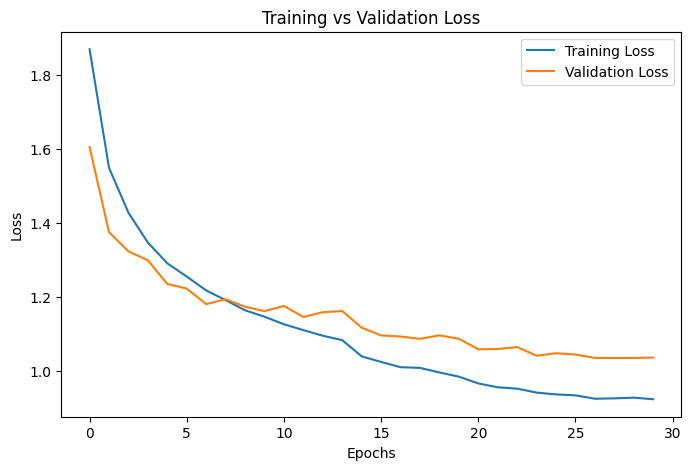

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

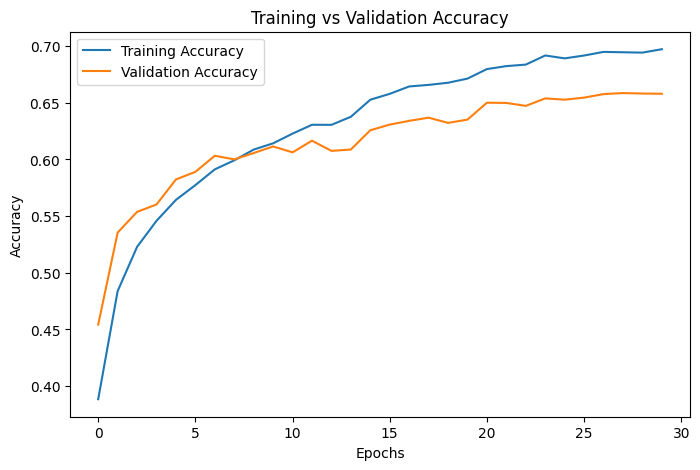

In [ ]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Save the training history
import pickle
with open('training_history.pkl', 'wb') as file:
    pickle.dump(history.history, file)

print("Training history saved successfully!")

Training history saved successfully!


In [ ]:
# Evaluate the trained model using test dataset
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 89ms/step - accuracy: 0.6615 - loss: 1.0355
Test Loss: 1.0355209112167358
Test Accuracy: 0.6614999771118164
Test Accuracy (%): 66.14999771118164


In [ ]:
#Predictions
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([labels.numpy().flatten()
    for images, labels in test_ds
])
print("Predicted labels:", y_pred_classes.shape)
print("Actual labels:", y_true.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 106ms/step
Predicted labels: (10000,)
Actual labels: (10000,)


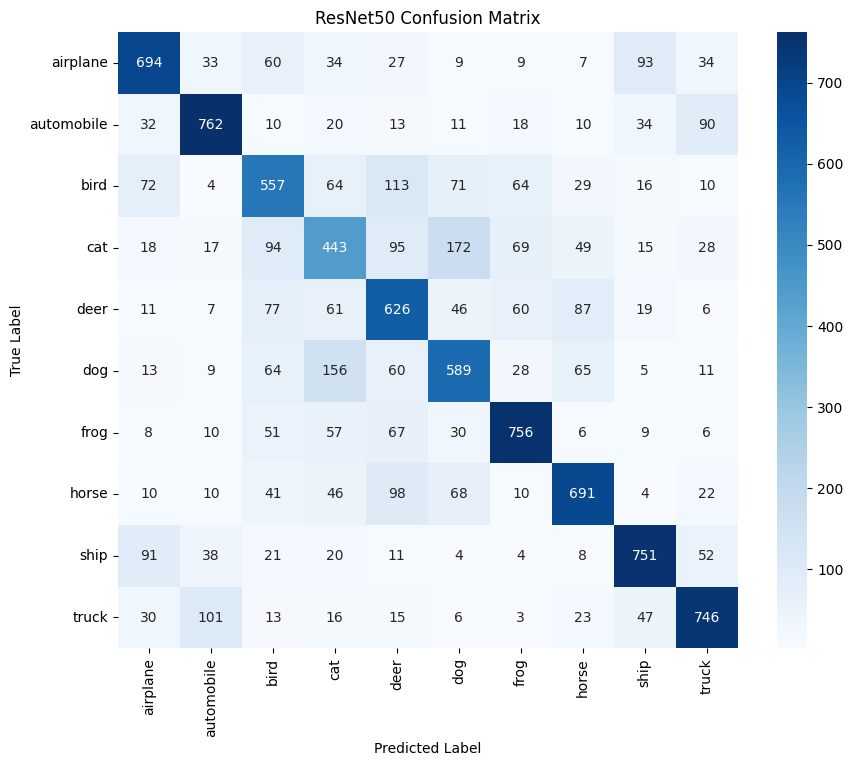

In [ ]:
#Confusion matrix
# Define CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('ResNet50 Confusion Matrix')
plt.show()

In [ ]:
#classification report
report = classification_report(y_true,y_pred_classes,target_names=class_names)
print(report)

              precision    recall  f1-score   support

    airplane       0.71      0.69      0.70      1000
  automobile       0.77      0.76      0.77      1000
        bird       0.56      0.56      0.56      1000
         cat       0.48      0.44      0.46      1000
        deer       0.56      0.63      0.59      1000
         dog       0.59      0.59      0.59      1000
        frog       0.74      0.76      0.75      1000
       horse       0.71      0.69      0.70      1000
        ship       0.76      0.75      0.75      1000
       truck       0.74      0.75      0.74      1000

    accuracy                           0.66     10000
   macro avg       0.66      0.66      0.66     10000
weighted avg       0.66      0.66      0.66     10000



##Why Early Stopping Helps in Transfer Learning?
Early Stopping prevents overfitting by stopping training when validation loss stops improving. It helps preserve the pretrained model's useful features and avoids unnecessary training.

##Why Weight Decay is Important?
Weight decay reduces overfitting by penalizing large weights. It helps keep model weights small, improves generalization, and makes the model perform better on unseen data.

##Part 4: Fine-Tuning

In [ ]:
# Store feature extraction performance
before_loss, before_accuracy = model.evaluate(test_ds)
print("Before Fine-Tuning Loss:", before_loss)
print("Before Fine-Tuning Accuracy:", before_accuracy)
print("Before Fine-Tuning Accuracy (%):", before_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 88ms/step - accuracy: 0.6615 - loss: 1.0355
Before Fine-Tuning Loss: 1.0355209112167358
Before Fine-Tuning Accuracy: 0.6614999771118164
Before Fine-Tuning Accuracy (%): 66.14999771118164


In [ ]:
# Unfreeze the ResNet50 backbone
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers[-20:]:
    print(layer.name, layer.trainable)
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

conv5_block2_1_conv True
conv5_block2_1_bn True
conv5_block2_1_relu True
conv5_block2_2_conv True
conv5_block2_2_bn True
conv5_block2_2_relu True
conv5_block2_3_conv True
conv5_block2_3_bn True
conv5_block2_add True
conv5_block2_out True
conv5_block3_1_conv True
conv5_block3_1_bn True
conv5_block3_1_relu True
conv5_block3_2_conv True
conv5_block3_2_bn True
conv5_block3_2_relu True
conv5_block3_3_conv True
conv5_block3_3_bn True
conv5_block3_add True
conv5_block3_out True


In [ ]:
# Train the model with a very small learning rate
model.compile(optimizer=AdamW(learning_rate=1e-5,weight_decay=0.0001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
# Reduce learning rate when validation loss stops improving
fine_lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Stop training if validation loss does not improve
fine_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save the best fine-tuned model
fine_checkpoint = ModelCheckpoint(
    'finetuned_resnet50.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [ ]:
# Train the model after unfreezing the last 20 layers
history_fine = model.fit(train_ds,validation_data=val_ds,epochs=15,
        callbacks=[
        fine_lr_scheduler,
        fine_early_stopping,
        fine_checkpoint
    ]
)

Epoch 1/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.6753 - loss: 0.9746
Epoch 1: val_loss improved from None to 1.08154, saving model to finetuned_resnet50.keras

Epoch 1: finished saving model to finetuned_resnet50.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 190s 139ms/step - accuracy: 0.6783 - loss: 0.9658 - val_accuracy: 0.6394 - val_loss: 1.0815 - learning_rate: 1.0000e-05
Epoch 2/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.6949 - loss: 0.9174
Epoch 2: val_loss improved from 1.08154 to 1.06314, saving model to finetuned_resnet50.keras

Epoch 2: finished saving model to finetuned_resnet50.keras
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 166s 133ms/step - accuracy: 0.6988 - loss: 0.9102 - val_accuracy: 0.6457 - val_loss: 1.0631 - learning_rate: 1.0000e-05
Epoch 3/15
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7113 - loss: 0.8772
Epoch 3: val_loss did not improve from 1.06314
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 165s 132ms/step - accuracy: 0.7149 - loss: 0.86

In [ ]:
print("Before Fine-Tuning Test Accuracy :", before_accuracy * 100)
print("After Fine-Tuning Test Accuracy :", fine_test_accuracy * 100)

Before Fine-Tuning Test Accuracy : 65.85999727249146
After Fine-Tuning Test Accuracy : 70.96999883651733


In [ ]:
# Compare validation accuracy before and after fine-tuning
before_val_accuracy = max(history.history['val_accuracy'])
after_val_accuracy = max(history_fine.history['val_accuracy'])

print("Before Fine-Tuning Validation Accuracy:", before_val_accuracy)
print("After Fine-Tuning Validation Accuracy:", after_val_accuracy)

Before Fine-Tuning Validation Accuracy: 0.6585999727249146
After Fine-Tuning Validation Accuracy: 0.70660001039505


In [ ]:
# Generate predictions using the fine-tuned model
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([labels.numpy().flatten()
    for images, labels in test_ds
])

313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 102ms/step


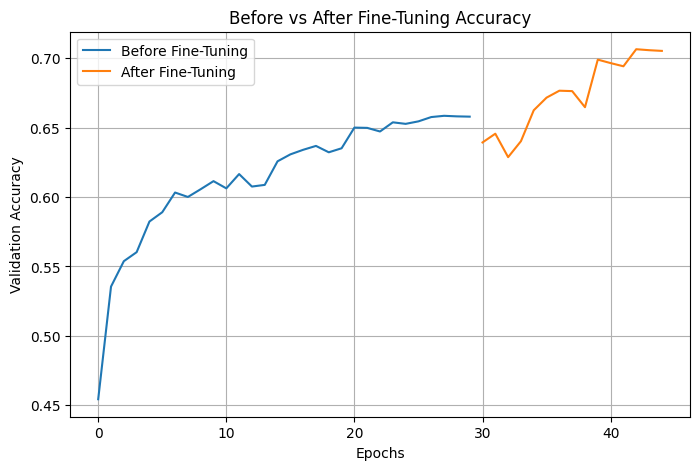

In [ ]:
# Plot validation accuracy before and after fine-tuning
plt.figure(figsize=(8, 5))
plt.plot(
    history.history['val_accuracy'],
    label='Before Fine-Tuning'
)

plt.plot(
    range(len(history.history['val_accuracy']),
          len(history.history['val_accuracy']) + len(history_fine.history['val_accuracy'])),
    history_fine.history['val_accuracy'],
    label='After Fine-Tuning'
)

plt.title('Before vs After Fine-Tuning Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Validation Accuracy')

plt.legend()

plt.grid()

plt.show()

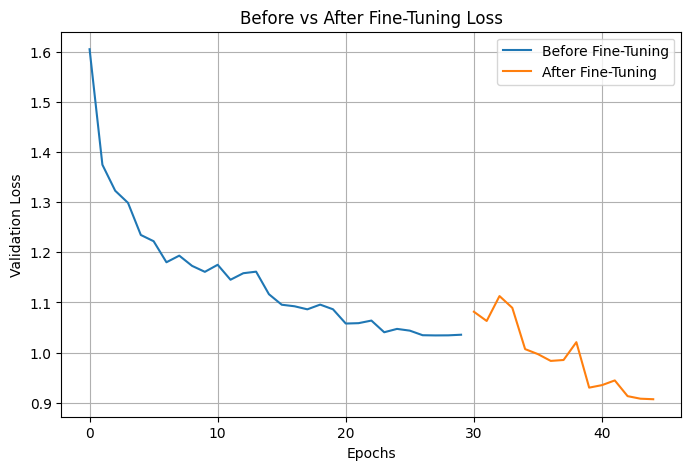

In [ ]:
# Plot validation loss before and after fine-tuning
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['val_loss'],
    label='Before Fine-Tuning'
)

plt.plot(
    range(len(history.history['val_loss']),
          len(history.history['val_loss']) + len(history_fine.history['val_loss'])),
    history_fine.history['val_loss'],
    label='After Fine-Tuning'
)

plt.title('Before vs After Fine-Tuning Loss')

plt.xlabel('Epochs')

plt.ylabel('Validation Loss')

plt.legend()

plt.grid()

plt.show()

##After fine-tuning, validation accuracy improved from 65.86% to 70.66%, showing better classification performance. However, overfitting also increased, as the training-validation accuracy gap grew from 3.87% to 11.79%. This indicates that fine-tuning improved learning but reduced the model's generalization ability to some extent.

#Part 5: Evaluation

In [ ]:
# Load the best saved fine-tuned ResNet50 model
model = keras.models.load_model('finetuned_resnet50.keras')

In [ ]:
# Generate predictions
y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([labels.numpy().flatten()
    for images, labels in test_ds
])

print("Predicted labels:", y_pred_classes.shape)
print("Actual labels:", y_true.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step
Predicted labels: (10000,)
Actual labels: (10000,)


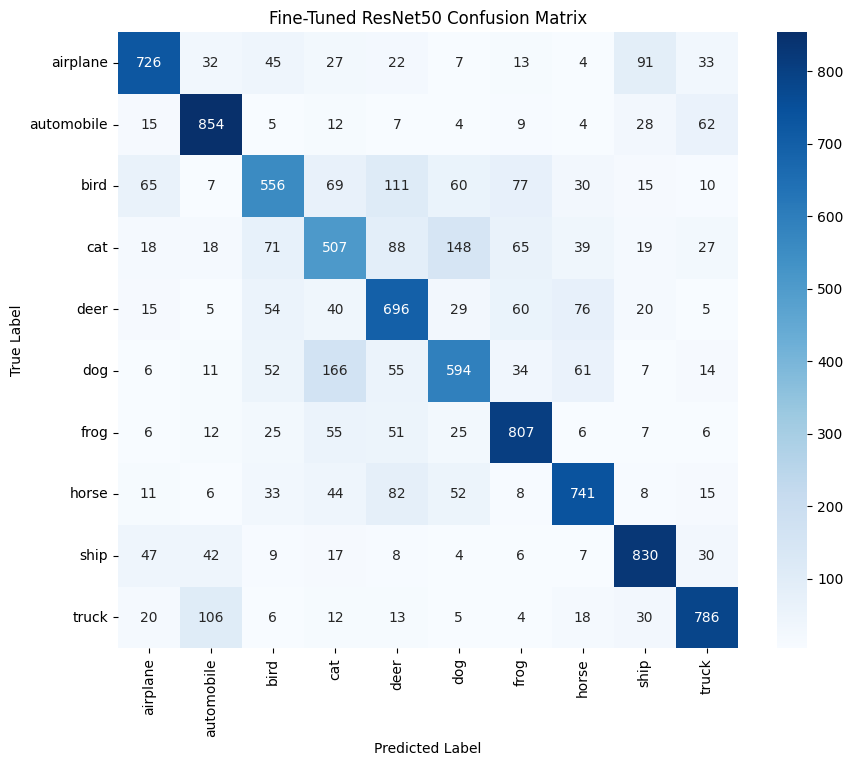

In [ ]:
# Confusion Matrix
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=class_names,yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Fine-Tuned ResNet50 Confusion Matrix')
plt.show()

In [ ]:
#  per-class accuracy
per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
print("Per-Class Accuracy:")
for i, accuracy in enumerate(per_class_accuracy):
    print(f"{class_names[i]}: {accuracy * 100:.2f}%")

Per-Class Accuracy:
airplane: 72.60%
automobile: 85.40%
bird: 55.60%
cat: 50.70%
deer: 69.60%
dog: 59.40%
frog: 80.70%
horse: 74.10%
ship: 83.00%
truck: 78.60%


In [ ]:
# classification report
report = classification_report(y_true,y_pred_classes,target_names=class_names)
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

    airplane       0.78      0.73      0.75      1000
  automobile       0.78      0.85      0.82      1000
        bird       0.65      0.56      0.60      1000
         cat       0.53      0.51      0.52      1000
        deer       0.61      0.70      0.65      1000
         dog       0.64      0.59      0.62      1000
        frog       0.75      0.81      0.77      1000
       horse       0.75      0.74      0.75      1000
        ship       0.79      0.83      0.81      1000
       truck       0.80      0.79      0.79      1000

    accuracy                           0.71     10000
   macro avg       0.71      0.71      0.71     10000
weighted avg       0.71      0.71      0.71     10000



In [ ]:
# Identify the hardest classes
hardest_indices = np.argsort(per_class_accuracy)[:3]
print("Top 3 Hardest Classes:")
for i in hardest_indices:
    print(
        f"{class_names[i]}: "
        f"{per_class_accuracy[i] * 100:.2f}% accuracy"
    )

Top 3 Hardest Classes:
cat: 50.70% accuracy
bird: 55.60% accuracy
dog: 59.40% accuracy
